# Car Price Prediction Using Machine Learning

## Project Description
The objective of this project is to predict the selling price of used cars using Machine Learning. The project uses vehicle details such as car age, present price, kilometers driven, fuel type, seller type, transmission, and ownership to estimate car prices.

## Importing Libraries

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Loading Dataset

In [3]:
from google.colab import files
uploaded = files.upload()

Saving car data.csv to car data.csv


In [4]:
import pandas as pd

df = pd.read_csv("car data.csv")
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## Data Cleaning

Dataset Information

In [5]:
df.shape

(301, 9)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [7]:
df.dtypes

,0
Car_Name,object
Year,int64
Selling_Price,float64
Present_Price,float64
Kms_Driven,int64
Fuel_Type,object
Seller_Type,object
Transmission,object
Owner,int64


Check Missing Values

In [8]:
df.isnull().sum()

,0
Car_Name,0
Year,0
Selling_Price,0
Present_Price,0
Kms_Driven,0
Fuel_Type,0
Seller_Type,0
Transmission,0
Owner,0


Check Duplicate Rows

In [9]:
df.duplicated().sum()

np.int64(2)

Remove Duplicate Rows

In [10]:
df.drop_duplicates(inplace=True)

print(df.shape)
print(df.duplicated().sum())

(299, 9)
0


In [11]:
print("Fuel_Type:", df["Fuel_Type"].unique())
print("Seller_Type:", df["Seller_Type"].unique())
print("Transmission:", df["Transmission"].unique())

Fuel_Type: ['Petrol' 'Diesel' 'CNG']
Seller_Type: ['Dealer' 'Individual']
Transmission: ['Manual' 'Automatic']


## Feature Engineering

In [12]:
df["Car_Age"] = 2026 - df["Year"]

df["Brand"] = df["Car_Name"].str.split().str[0]

df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Car_Age,Brand
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0,12,ritz
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0,13,sx4
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0,9,ciaz
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0,15,wagon
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0,12,swift


## Exploratory Data Analysis (EDA)

### Selling Price Distribution

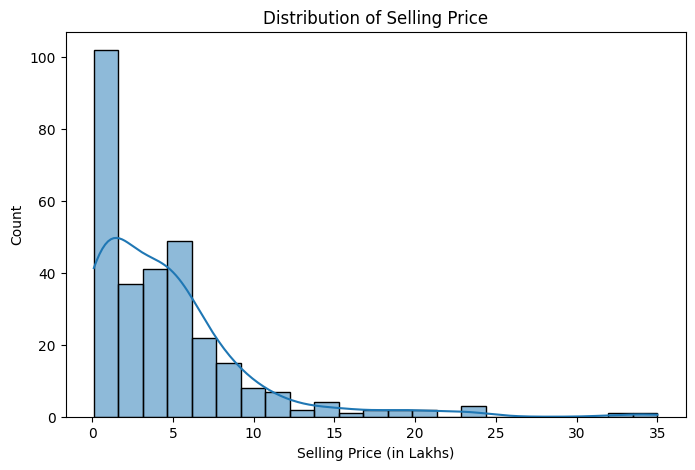

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df["Selling_Price"], kde=True)
plt.title("Distribution of Selling Price")
plt.xlabel("Selling Price (in Lakhs)")
plt.ylabel("Count")
plt.show()

### Selling Price vs Fuel Type

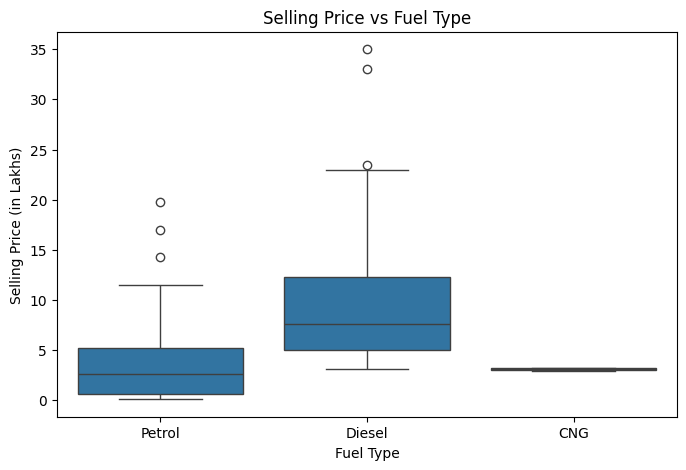

In [14]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="Fuel_Type", y="Selling_Price", data=df)
plt.title("Selling Price vs Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (in Lakhs)")
plt.show()

### Selling Price vs Car Age

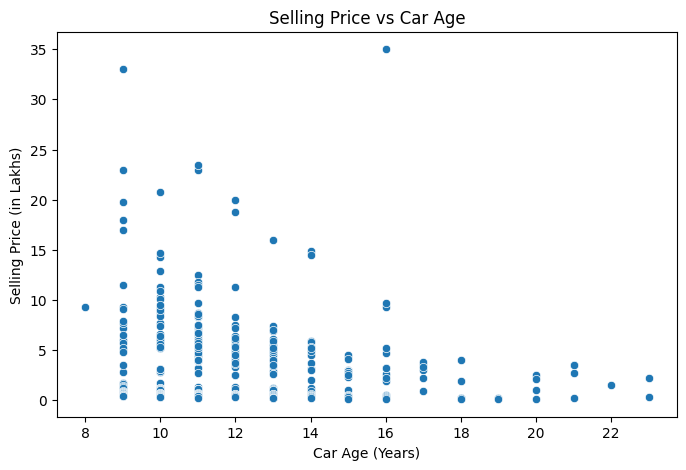

In [15]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x="Car_Age", y="Selling_Price", data=df)
plt.title("Selling Price vs Car Age")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price (in Lakhs)")
plt.show()

### Correlation Heatmap

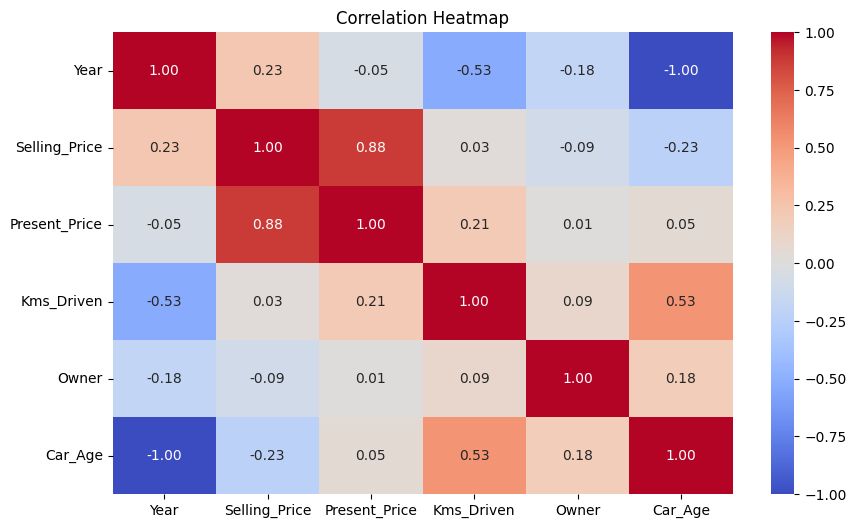

In [16]:
plt.figure(figsize=(10, 6))

numeric_df = df.select_dtypes(include=["number"])

sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

## Categorical Encoding

In [17]:
df_encoded = pd.get_dummies(
    df.drop(columns=["Car_Name"]),
    columns=["Fuel_Type", "Seller_Type", "Transmission", "Brand"],
    drop_first=True,
    dtype=int
)

df_encoded.head()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner,Car_Age,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Individual,Transmission_Manual,...,Brand_land,Brand_omni,Brand_ritz,Brand_s,Brand_swift,Brand_sx4,Brand_verna,Brand_vitara,Brand_wagon,Brand_xcent
0,2014,3.35,5.59,27000,0,12,0,1,0,1,...,0,0,1,0,0,0,0,0,0,0
1,2013,4.75,9.54,43000,0,13,1,0,0,1,...,0,0,0,0,0,1,0,0,0,0
2,2017,7.25,9.85,6900,0,9,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
3,2011,2.85,4.15,5200,0,15,0,1,0,1,...,0,0,0,0,0,0,0,0,1,0
4,2014,4.60,6.87,42450,0,12,1,0,0,1,...,0,0,0,0,1,0,0,0,0,0


## Train-Test Split

In [18]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop(columns=["Selling_Price"])
y = df_encoded["Selling_Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (239, 52)
Testing data: (60, 52)


## Linear Regression Model

In [19]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


## Random Forest Regression Model

In [20]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


## Model Evaluation

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Linear Regression Evaluation
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

# Random Forest Evaluation
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Linear Regression Results")
print("MAE:", mae_lr)
print("RMSE:", rmse_lr)
print("R2 Score:", r2_lr)

print("\nRandom Forest Results")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Linear Regression Results
MAE: 1.808783024362376
RMSE: 3.3993205771612947
R2 Score: 0.5516523951574543

Random Forest Results
MAE: 1.3684716666666672
RMSE: 3.3286570732303846
R2 Score: 0.5700987397081108


## Feature Importance Analysis

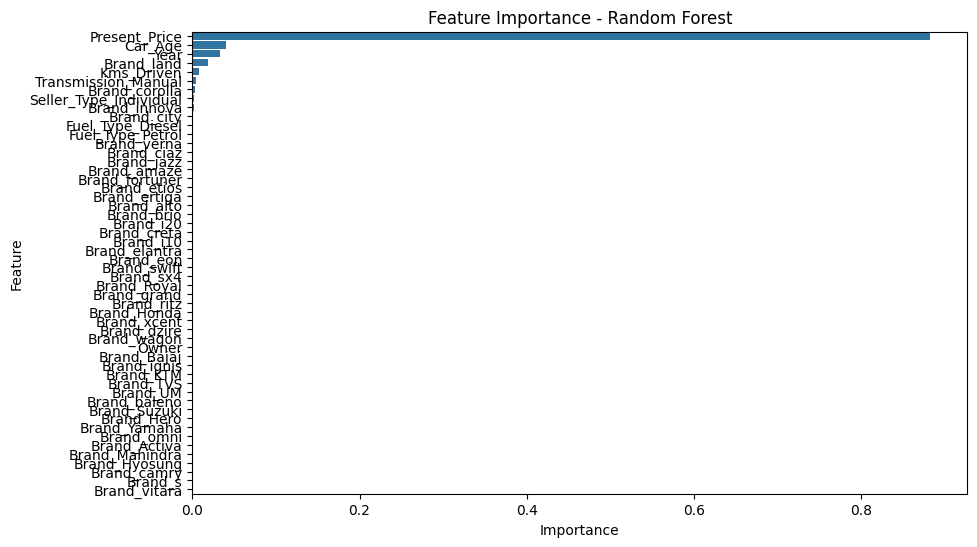

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x="Importance",
    y="Feature",
    data=feature_importance
)

plt.title("Feature Importance - Random Forest")
plt.show()

## Conclusion

In this project, a Car Price Prediction model was developed using Machine Learning techniques. The dataset was cleaned by removing duplicate records and checking missing values. Feature engineering was performed by calculating car age and extracting the brand name. Exploratory Data Analysis (EDA) was conducted using graphs and a correlation heatmap.

Linear Regression and Random Forest Regression models were trained and evaluated using MAE, RMSE, and R² Score. Both models were compared to identify the better-performing model. Feature importance analysis was also performed to understand the factors influencing car selling prices.

This project demonstrates how Machine Learning can be used to predict the selling price of used cars based on their features.